# Algoritmo di Grover: dalla simulazione ideale all'hardware IBM

## 1. Introduzione e obiettivi
In questo notebook studio l'algoritmo di Grover attraverso un'implementazione in Python con Qiskit. Costruisco esplicitamente l'oracolo e il diffusore per osservare come il cambio di fase della soluzione si trasformi in un aumento della sua probabilità di misura.

L'obiettivo è confrontare il comportamento previsto dalla teoria con i risultati delle simulazioni e delle esecuzioni su hardware IBM. In particolare, cerco di capire come scegliere il numero di iterazioni, che cosa succede quando se ne eseguono troppe (*overshooting*) e come cambiano i risultati al variare del numero di qubit e delle soluzioni da cercare.

Il percorso comprende tre modalità: simulazione ideale, simulazione con rumore ed esecuzione su un dispositivo quantistico reale. Questo confronto permette di distinguere le fluttuazioni dovute al campionamento delle misure dagli effetti degli errori del dispositivo.

## 2. Descrizione degli esperimenti
Parto dalla verifica dell'oracolo e del diffusore e confronto le probabilità calcolate con `Statevector` con la previsione teorica di Grover. Eseguo poi misure ripetute con `AerSimulator`: ogni *shot* corrisponde a una ripetizione del circuito con misura finale. Ripetendo lo stesso esperimento, osservo quanto le frequenze misurate si discostino dalle probabilità ideali.

Dopo gli esperimenti ideali introduco il rumore attraverso i fake backend IBM `FakeManilaV2`, `FakeNairobiV2` e `FakeMumbaiV2`. Questi modelli permettono di simulare alcuni errori dei dispositivi, senza eseguire il circuito su una QPU reale. Studio inoltre l'aumento della dimensione dello spazio di ricerca, la presenza di più soluzioni e il caso in cui il loro numero non sia noto, affrontato con una ricerca randomizzata.

Infine eseguo circuiti su hardware IBM e analizzo i risultati salvati, confrontandoli con il caso ideale. Grafici e tabelle accompagnano i test per evidenziare l'amplificazione della soluzione, le oscillazioni della probabilità al variare delle iterazioni e i limiti osservati in presenza di rumore.

## 3. Import e configurazione dell'ambiente
Carico le librerie necessarie e stampo le versioni per documentare l'ambiente usato. Per eseguire il notebook seleziono il kernel **Python (Grover)** oppure l'interprete `.venv/Scripts/python.exe`.

Uso `AerSimulator` del pacchetto `qiskit_aer` per le simulazioni, `transpile` per compilare i circuiti e `backend.run` per eseguirli.

[Documentazione di AerSimulator](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html)

In [70]:
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate
from qiskit_aer import AerSimulator

LIBRARY_VERSIONS = {
    name: version(name)
    for name in ("qiskit", "qiskit-aer", "numpy", "pandas", "matplotlib")
}
print(f"Python: {sys.version.split()[0]}")
for name, installed_version in LIBRARY_VERSIONS.items():
    print(f"{name}: {installed_version}")
from qiskit.quantum_info import Operator, Statevector
from IPython.display import display
from qiskit import transpile
from time import perf_counter
from pathlib import Path
from collections.abc import Mapping
import json


Python: 3.12.0
qiskit: 2.5.2
qiskit-aer: 0.17.2
numpy: 2.4.4
pandas: 3.0.2
matplotlib: 3.10.9


## 4. Parametri globali
Raccolgo i valori iniziali e il seme casuale. Gli stati sono stringhe nell'ordine Qiskit `q[n-1]...q[0]`: il bit più a destra corrisponde al qubit 0. Parto da una soluzione; la tupla consente di rappresentarne più di una.

In [71]:
RANDOM_SEED = 42
SHOTS_DEFAULT = 4096
N_VALUES = (2, 3, 4, 5, 6)  # Dimensioni per gli esperimenti ideali con shots.
N_QUBITS_DEFAULT = N_VALUES[1]
MARKED_STATE_DEFAULT = "101"
MARKED_STATES_DEFAULT = (MARKED_STATE_DEFAULT,)
SEARCH_SPACE_SIZE = 2 ** N_QUBITS_DEFAULT
N_SOLUTIONS_DEFAULT = len(MARKED_STATES_DEFAULT)

rng = np.random.default_rng(RANDOM_SEED)


def validate_problem(n: int, marked_states: list[str] | tuple[str, ...]) -> None:
    """Controlla dimensione, alfabeto binario e unicità delle soluzioni."""
    if isinstance(n, bool) or not isinstance(n, int) or n < 1:
        raise ValueError("n deve essere un intero positivo.")
    if not isinstance(marked_states, (list, tuple)):
        raise ValueError("marked_states deve essere una lista o tupla di bitstring.")
    if not marked_states:
        raise ValueError("Occorre almeno una soluzione marcata.")
    if any(not isinstance(state, str) or len(state) != n
           or set(state) - {"0", "1"} for state in marked_states):
        raise ValueError("Ogni stato deve essere una stringa binaria di lunghezza n.")
    if len(set(marked_states)) != len(marked_states):
        raise ValueError("Gli stati marcati devono essere distinti.")


def make_ideal_backend(seed: int = RANDOM_SEED) -> AerSimulator:
    """Crea un simulatore ideale riproducibile con la base di porte del progetto."""
    return AerSimulator(method="statevector", basis_gates=["u", "cx"], seed_simulator=seed)


validate_problem(N_QUBITS_DEFAULT, MARKED_STATES_DEFAULT)

### Tabella centrale degli esperimenti
Schema e impostazioni comuni per le esecuzioni con shots.

In [72]:
# Ogni riga raccoglie i risultati di un circuito eseguito con un dato numero di shot.
RESULT_DTYPES = {
    "backend": "string", "mode": "string", "n": "Int64", "N": "Int64", "M": "Int64",
    "marked_states": "object", "k": "Int64", "shots": "Int64",
    "theoretical_probability": "Float64", "measured_success_probability": "Float64",
    "execution_time": "Float64", "depth": "Int64", "total_gate_count": "Int64",
    "two_qubit_gate_count": "Int64", "standard_error": "Float64",
    "seed": "Int64", "seed_transpiler": "Int64", "optimization_level": "Int64",
    "basis_gates": "object", "counts": "object", "normalized_counts": "object",
    "qiskit_version": "string", "qiskit_aer_version": "string",
}
RESULT_DTYPES.update({
    "p1": "Float64", "p2": "Float64", "readout_error": "Float64",
    "success_probability": "Float64", "expected_noisy_probability": "Float64",
    "actual_basis_gates": "string", "simulation_method": "string", "experiment_group": "string",
})
def make_results_dataframe() -> pd.DataFrame:
    return pd.DataFrame({name: pd.Series(dtype=dtype) for name, dtype in RESULT_DTYPES.items()})

results_df = make_results_dataframe()
IDEAL_BASIS_GATES = ("u", "cx")
IDEAL_OPTIMIZATION_LEVEL = 1

## 5. Costruzione dell'oracolo
L'oracolo cambia il segno dell'ampiezza delle soluzioni, lasciando invariate le altre. Per una sola soluzione scrivo $O=I-2|w\rangle\langle w|$; per un insieme $W$ di soluzioni distinte:
$$O_W=I-2\sum_{w\in W}|w\rangle\langle w|.$$
Per ogni stringa applico X ai qubit corrispondenti ai bit zero, una Z multicontrollata e infine le stesse X. In questo modo il cambio di fase su $|11\ldots1\rangle$ riguarda lo stato scelto. Escludo le stringhe duplicate: marcare due volte lo stesso stato annullerebbe il cambio di segno.

Le stringhe seguono l'ordine `q[n-1]...q[0]`: il bit a destra corrisponde al qubit 0. Per esempio, `101` ha indice 5 nel vettore di stato, mentre `001` ha indice 1. Nel codice inverto la stringa per associare ogni bit al qubit corretto.

[Ordine dei bit in Qiskit](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering)

Adatto l'oracolo del tutorial IBM mantenendo i parametri e i controlli del notebook. La funzione di supporto usa Z per un qubit e `MCMTGate(ZGate(), n - 1, 1)` per due o più qubit, senza aggiungere un'ancilla al circuito logico.

[Tutorial IBM su Grover](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm)

In [73]:
def apply_multi_controlled_z(circuit: QuantumCircuit) -> None:
    """Applica in-place la fase -1 su |11...1> a tutti i qubit."""
    n = circuit.num_qubits
    if n < 1:
        raise ValueError("La Z multi-controllata richiede almeno un qubit.")
    if n == 1:
        circuit.z(0)
    else:
        circuit.compose(MCMTGate(ZGate(), n - 1, 1), inplace=True)



def build_phase_oracle(
    n_qubits: int, marked_states: list[str] | tuple[str, ...]
) -> QuantumCircuit:
    """Costruisce O_W; stringhe in ordine q[n-1]...q[0]."""
    validate_problem(n_qubits, marked_states)
    circuit = QuantumCircuit(n_qubits, name="O")
    # Adattato da https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm
    for target in marked_states:
        rev_target = target[::-1]  # Il bit a destra corrisponde al qubit 0.
        zero_inds = [ind for ind, bit in enumerate(rev_target) if bit == "0"]
        if zero_inds:
            circuit.x(zero_inds)
        apply_multi_controlled_z(circuit)
        if zero_inds:
            circuit.x(zero_inds)
    return circuit


def build_oracle(n: int, marked_states: list[str] | tuple[str, ...]) -> QuantumCircuit:
    """Alias compatibile con la firma già prevista nel notebook."""
    return build_phase_oracle(n, marked_states)

## 6. Costruzione del diffusore
Il diffusore realizza $D=2|s\rangle\langle s|-I$, dove $|s\rangle$ indica la sovrapposizione uniforme. Il suo effetto sulle ampiezze si descrive come una riflessione rispetto alla loro media:
$$a'_x=2\bar a-a_x, \qquad \bar a=\frac{1}{N}\sum_x a_x.$$
Dopo il cambio di segno introdotto dall'oracolo, questa operazione permette di amplificare le soluzioni.

La sequenza H, X, Z multicontrollata, X, H realizza $-D$. Per ottenere esattamente $D$ uso `grover_operator` con un oracolo identità: dato che la funzione costruisce $DO$, ponendo $O=I$ rimane solo il diffusore. Qiskit include già la fase globale corretta. L'oracolo delle soluzioni viene applicato separatamente nella sezione 7.

La fase globale non cambia le probabilità, ma tenerne conto permette di confrontare direttamente le ampiezze con le formule. Non aggiungo qubit ausiliari per la compilazione.

[grover_operator](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.grover_operator)

In [74]:
def build_diffuser(n_qubits: int) -> QuantumCircuit:
    """Costruisce D = 2|s><s| - I, inclusa la fase globale."""
    if isinstance(n_qubits, bool) or not isinstance(n_qubits, int) or n_qubits < 1:
        raise ValueError("n_qubits deve essere un intero positivo.")
    # grover_operator costruisce D O: con O=I ottengo solo il diffusore.
    # L'oracolo vero viene applicato separatamente da build_grover_circuit.
    identity_oracle = QuantumCircuit(n_qubits)
    circuit = grover_operator(identity_oracle)
    circuit.name = "D"
    # La fase globale corretta è già inclusa da Qiskit.
    return circuit


### 6.1 Circuiti a tre qubit: stato marcato |101⟩
I diagrammi testuali mostrano le porte senza dipendenze grafiche aggiuntive.

In [75]:
oracle_example = build_phase_oracle(3, ["101"])
diffuser_example = build_diffuser(3)
print("Phase oracle, stato marcato |101>:")
print(oracle_example.draw(output="text"))
print("Diffusore (fase globale pi inclusa):")
print(diffuser_example.draw(output="text"))

Phase oracle, stato marcato |101>:
           1-Z      
q_0: ───────■───────
     ┌───┐  │  ┌───┐
q_1: ┤ X ├──■──┤ X ├
     └───┘  │  └───┘
q_2: ───────■───────
                    
Diffusore (fase globale pi inclusa):
global phase: π
     ┌───┐┌───┐          ┌───┐┌───┐     
q_0: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤       │  ├───┤├───┤     
q_1: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐
q_2: ┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘└───┘└───┘└───┘└───┘


### 6.2 Verifica delle ampiezze e tabella
Preparo $|s\rangle$ con Hadamard e confronto le ampiezze con formule indipendenti dai circuiti.
Per $N=8,M=1$, dopo l'oracolo $\bar a=3/(4\sqrt8)$; dopo il diffusore
l'ampiezza marcata vale $5/(2\sqrt8)$ e le altre $1/(2\sqrt8)$.
Gli assert usano tolleranza assoluta $10^{-12}$ e relativa zero.

In [76]:
ATOL = 1e-12
prepare_uniform = QuantumCircuit(3)
prepare_uniform.h(range(3))
before_oracle = Statevector.from_instruction(prepare_uniform)
after_oracle = before_oracle.evolve(oracle_example)
after_diffuser = after_oracle.evolve(diffuser_example)
expected_before = np.full(8, 1 / np.sqrt(8), dtype=complex)
expected_after = expected_before.copy()
expected_after[5] *= -1
expected_diffused = 2 * expected_after.mean() - expected_after
np.testing.assert_allclose(before_oracle.data, expected_before, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_oracle.data, expected_after, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_diffuser.data, expected_diffused, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_diffuser.data[5], 5 / (2 * np.sqrt(8)), atol=ATOL, rtol=0)
np.testing.assert_allclose(np.linalg.norm(after_diffuser.data), 1, atol=ATOL, rtol=0)
amplitudes_df = pd.DataFrame({
    "basis_state": [format(i, "03b") for i in range(8)],
    "amplitude_before_oracle": np.real_if_close(before_oracle.data),
    "amplitude_after_oracle": np.real_if_close(after_oracle.data),
    "amplitude_after_diffuser": np.real_if_close(after_diffuser.data),
})
display(amplitudes_df)

,basis_state,amplitude_before_oracle,amplitude_after_oracle,amplitude_after_diffuser
0,000,0.353553,0.353553,0.176777
1,001,0.353553,0.353553,0.176777
2,010,0.353553,0.353553,0.176777
3,011,0.353553,0.353553,0.176777
4,100,0.353553,0.353553,0.176777
5,101,0.353553,-0.353553,0.883883
6,110,0.353553,0.353553,0.176777
7,111,0.353553,0.353553,0.176777


## 7. Costruzione dell'algoritmo di Grover
QuantumCircuit parte da |0...0⟩; gli Hadamard preparano lo stato uniforme.
Ogni iterazione applica prima l'oracolo, poi il diffusore costruiti dalle funzioni precedenti.
Con zero iterazioni rimane la sovrapposizione uniforme. Le misure opzionali associano
il qubit i al bit classico i, mantenendo le stringhe nell'ordine q[n-1]...q[0].
Per Statevector uso sempre measure=False.

In [77]:
def build_grover_circuit(
    n_qubits: int,
    marked_states: list[str] | tuple[str, ...],
    iterations: int,
    measure: bool = True,
) -> QuantumCircuit:
    """Prepara lo stato uniforme, applica (D O)^iterations e misura opzionalmente."""
    validate_problem(n_qubits, marked_states)
    if isinstance(iterations, bool) or not isinstance(iterations, (int, np.integer)) or iterations < 0:
        raise ValueError("iterations deve essere un intero non negativo.")
    if not isinstance(measure, bool):
        raise ValueError("measure deve essere booleano.")
    circuit = QuantumCircuit(n_qubits, n_qubits if measure else 0, name="Grover")
    circuit.h(range(n_qubits))
    if iterations:
        oracle = build_phase_oracle(n_qubits, marked_states)
        diffuser = build_diffuser(n_qubits)
        for _ in range(iterations):
            circuit.compose(oracle, inplace=True)
            circuit.compose(diffuser, inplace=True)
    if measure:
        circuit.measure(range(n_qubits), range(n_qubits))
    return circuit

## 8. Probabilità di successo e scelta delle iterazioni
Con $n$ qubit abbiamo $N=2^n$ stati possibili. Indico con $M$ il numero di soluzioni: prima di applicare Grover, la probabilità di trovarne una è $M/N$.

Ogni iterazione applica oracolo e diffusore. All'inizio la probabilità di successo aumenta, ma **fare più iterazioni non significa sempre ottenere un risultato migliore**: dopo il primo massimo può diminuire. Questo effetto si chiama **overshooting**.

Nel caso ideale, dopo $k$ iterazioni la probabilità di misurare una qualsiasi delle soluzioni è:
$$P(k)=\sin^2((2k+1)\theta), \qquad \theta=\arcsin\sqrt{M/N}.$$
L'angolo $\theta$ dipende dalla frazione di stati che sono soluzioni. Geometricamente, ogni iterazione ruota lo stato di $2\theta$: bisogna fermarsi vicino alla direzione delle soluzioni, prima di oltrepassarla.

**Scelta delle iterazioni.** Il primo massimo della formula si trova in:
$$k_* = \frac{\pi}{4\theta}-\frac{1}{2}.$$
Questo valore non è necessariamente intero. La cella seguente confronta quindi i due interi non negativi vicini a $k_*$ e sceglie quello con probabilità maggiore; in caso di parità sceglie il minore. Per esempio, con **3 qubit e una soluzione**, sceglie **2 iterazioni**, con probabilità ideale del **94,53%**.

Quando le soluzioni sono poche rispetto a $N$, una stima comune è $k\approx(\pi/4)\sqrt{N/M}$. La tabella confronta questa stima con il massimo continuo e con il numero intero scelto. Se tutti gli stati sono soluzioni ($M=N$), bastano invece zero iterazioni: il successo è già certo.

In [78]:
def grover_theta(N: int, M: int) -> float:
    """Restituisce arcsin(sqrt(M/N)); richiede 1 <= M <= N interi."""
    if any(isinstance(v, bool) or not isinstance(v, (int, np.integer)) for v in (N, M)):
        raise ValueError("N e M devono essere interi.")
    if N < 1 or not 1 <= M <= N:
        raise ValueError("Occorre 1 <= M <= N.")
    return float(np.arcsin(np.sqrt(M / N)))


def theoretical_success_probability(N: int, M: int, k: int) -> float:
    """Probabilità ideale dopo k iterazioni intere non negative."""
    theta = grover_theta(N, M)
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 0:
        raise ValueError("k deve essere un intero non negativo.")
    if M == N:
        return 1.0
    return float(np.sin((2 * k + 1) * theta) ** 2)


def optimal_grover_iterations(N: int, M: int) -> int:
    """Sceglie tra gli interi vicini al primo massimo; parità -> meno iterazioni."""
    theta = grover_theta(N, M)
    if M == N:
        return 0
    continuous = np.pi / (4 * theta) - 0.5
    lower = max(0, int(np.floor(continuous)))
    upper = max(0, int(np.ceil(continuous)))
    p_lower = theoretical_success_probability(N, M, lower)
    p_upper = theoretical_success_probability(N, M, upper)
    return upper if p_upper > p_lower + 1e-14 else lower


iteration_choices_df = pd.DataFrame([
    {"n": n, "N": 2 ** n, "M": 1,
     "approximate_k": np.pi / 4 * np.sqrt(2 ** n),
     "first_continuous_maximum": np.pi / (4 * grover_theta(2 ** n, 1)) - 0.5,
     "chosen_k": optimal_grover_iterations(2 ** n, 1)}
    for n in (2, 3, 4)
])
display(iteration_choices_df)

,n,N,M,approximate_k,first_continuous_maximum,chosen_k
0,2,4,1,1.570796,1.000000,1
1,3,8,1,2.221441,1.673408,2
2,4,16,1,3.141593,2.608269,3


## 9. Verifiche ideali con Statevector
Per $N=4,M=1$, $\theta=\pi/6$ e $3\theta=\pi/2$: una singola iterazione
produce lo stato marcato con probabilità 1. Verifico anche le ampiezze dello stato completo.
La tabella confronta teoria e simulazione per n=2,3,4 e k=0,...,8, includendo il primo
massimo e l'overshooting. Il successo è la somma delle probabilità degli stati marcati.
Uso tolleranza assoluta $10^{-12}$ e relativa zero; non ci sono fluttuazioni dovute al campionamento delle misure.

In [79]:
special_state = Statevector.from_instruction(build_grover_circuit(2, ["01"], 1, False))
np.testing.assert_allclose(special_state.data, Statevector.from_label("01").data, atol=ATOL, rtol=0)
np.testing.assert_allclose(theoretical_success_probability(4, 1, 1), 1, atol=ATOL, rtol=0)
assert optimal_grover_iterations(4, 1) == 1
print(f"N=4, M=1, k=1: P(|01>) = {special_state.probabilities()[1]:.15f}")

single_solution_cases = {2: ["01"], 3: ["101"], 4: ["0101"]}
comparison_rows = []
for n, marked in single_solution_cases.items():
    N, M = 2 ** n, len(marked)
    indices = [int(state, 2) for state in marked]
    for k in range(9):
        state = Statevector.from_instruction(build_grover_circuit(n, marked, k, False))
        probability = float(state.probabilities()[indices].sum())
        theory = theoretical_success_probability(N, M, k)
        np.testing.assert_allclose(probability, theory, atol=ATOL, rtol=0)
        np.testing.assert_allclose(np.linalg.norm(state.data), 1, atol=ATOL, rtol=0)
        comparison_rows.append({
            "n": n, "N": N, "M": M, "k": k,
            "theoretical_probability": theory, "statevector_probability": probability,
            "absolute_error": abs(probability - theory),
        })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
print(f"Errore assoluto massimo: {comparison_df.absolute_error.max():.3e}")

# Controllo anche i casi limite: zero iterazioni, un qubit e tutte le soluzioni.
for n, marked in ((1, ["0"]), (1, ["0", "1"]), (3, ["001", "110"])):
    for k in range(5):
        state = Statevector.from_instruction(build_grover_circuit(n, marked, k, False))
        np.testing.assert_allclose(
            state.probabilities()[[int(w, 2) for w in marked]].sum(),
            theoretical_success_probability(2 ** n, len(marked), k), atol=ATOL, rtol=0,
        )
zero_circuit = build_grover_circuit(3, ["001"], 0, False)
np.testing.assert_allclose(Statevector.from_instruction(zero_circuit).data,
                           np.full(8, 1 / np.sqrt(8)), atol=ATOL, rtol=0)
assert zero_circuit.num_clbits == 0
measured = build_grover_circuit(3, ["001"], 2)
measurements = [item for item in measured.data if item.operation.name == "measure"]
assert measured.num_clbits == 3 and len(measurements) == 3
assert [(measured.find_bit(item.qubits[0]).index, measured.find_bit(item.clbits[0]).index)
        for item in measurements] == [(0, 0), (1, 1), (2, 2)]
np.testing.assert_allclose(
    Operator(measured.remove_final_measurements(inplace=False)).data,
    Operator(build_grover_circuit(3, ["001"], 2, False)).data, atol=ATOL, rtol=0,
)
assert optimal_grover_iterations(8, 8) == 0
assert optimal_grover_iterations(8, 4) == 0  # Parità: P(k)=1/2.
for bad_call in (
    lambda: build_grover_circuit(2, ["01"], -1),
    lambda: build_grover_circuit(2, ["01"], 1.5),
    lambda: build_grover_circuit(2, ["01"], True),
    lambda: build_grover_circuit(2, ["01"], 1, "yes"),
    lambda: theoretical_success_probability(4, 1, -1),
    lambda: theoretical_success_probability(4, 1, 0.5),
    lambda: grover_theta(0, 1), lambda: grover_theta(4, 0),
    lambda: grover_theta(4, 5), lambda: grover_theta(4.0, 1),
):
    try:
        bad_call()
    except ValueError:
        pass
    else:
        raise AssertionError("Input non valido accettato.")
print("Il test conferma che il circuito quantistico costruito in Qiskit riproduce con infinita precisione la teoria dell'algoritmo di Grover.")

N=4, M=1, k=1: P(|01>) = 0.999999999999999


,n,N,M,k,theoretical_probability,statevector_probability,absolute_error
0,2,4,1,0,0.250000,0.250000,1.110223e-16
1,2,4,1,1,1.000000,1.000000,1.332268e-15
2,2,4,1,2,0.250000,0.250000,1.110223e-16
3,2,4,1,3,0.250000,0.250000,8.881784e-16
4,2,4,1,4,1.000000,1.000000,4.218847e-15
5,2,4,1,5,0.250000,0.250000,9.436896e-16
6,2,4,1,6,0.250000,0.250000,2.275957e-15
7,2,4,1,7,1.000000,1.000000,7.105427e-15
8,2,4,1,8,0.250000,0.250000,1.887379e-15
9,3,8,1,0,0.125000,0.125000,8.326673e-17


Errore assoluto massimo: 2.176e-14
Il test conferma che il circuito quantistico costruito in Qiskit riproduce con infinita precisione la teoria dell'algoritmo di Grover.


### 9.1 Primo esperimento statistico ideale
Ora passo dalle probabilità esatte alle **misure simulate**. Ogni circuito viene
eseguito 4096 volte (*shots*) su Aer, senza rumore.

Per ogni numero di qubit da 2 a 6 provo le iterazioni vicine al primo massimo
teorico. Lo stato cercato è sempre `00...01`.

L'esperimento segue tre passaggi:
1. Costruire e simulare il circuito di Grover.
2. Contare quante misure restituiscono lo stato cercato.
3. Confrontare la frequenza di successo con la probabilità teorica.

La frequenza è semplicemente **successi / shots**: per esempio, 3072 successi su
4096 misure danno 0,75. Con un numero finito di misure sono normali piccoli scarti
dalla teoria, anche senza rumore.

La funzione seguente raccoglie una singola esecuzione; la cella successiva la
ripete per i diversi valori di `n` e `k` e mostra una tabella riassuntiva.
I campi tecnici nel dizionario finale servono ai confronti e ai CSV delle sezioni
successive. L'errore standard stima la fluttuazione statistica della frequenza:
$\sqrt{\hat p(1-\hat p)/S}$. Non è un intervallo di confidenza; ai valori 0 e 1
si annulla senza dimostrare che l'incertezza sia nulla.


In [80]:
def success_probability(probabilities, marked_states):
    """Somma le probabilità degli stati cercati in una distribuzione normalizzata."""
    return float(sum(probabilities.get(state, 0.0) for state in marked_states))


def run_ideal_experiment(n_qubits, marked_states, iterations, shots, seed):
    """Simula Grover senza rumore e raccoglie il risultato."""
    circuit = build_grover_circuit(n_qubits, marked_states, iterations, measure=True)
    backend = make_ideal_backend(seed)
    compiled = transpile(circuit, backend,
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=seed)

    start = perf_counter()
    result = backend.run(compiled, shots=shots, seed_simulator=seed).result()
    execution_time = perf_counter() - start  # Tempo del simulatore, non di una QPU.
    counts = dict(result.get_counts())
    successes = sum(counts.get(state, 0) for state in marked_states)
    measured = successes / shots

    N, M = 2 ** n_qubits, len(marked_states)
    theory = theoretical_success_probability(N, M, iterations)

    normalized = {state: count / shots for state, count in counts.items()}
    gates_only = compiled.remove_final_measurements(inplace=False)
    gate_instructions = list(gates_only.data)
    return {
        "backend": backend.name, "mode": "ideal_shots", "n": n_qubits, "N": N, "M": M,
        "marked_states": tuple(marked_states), "k": iterations, "shots": int(shots),
        "theoretical_probability": theory, "measured_success_probability": measured,
        "execution_time": execution_time,
        "depth": gates_only.depth(),
        "total_gate_count": len(gate_instructions),
        "two_qubit_gate_count": sum(item.operation.num_qubits == 2 for item in gate_instructions),
        "standard_error": float(np.sqrt(measured * (1 - measured) / shots)),
        "seed": int(seed), "seed_transpiler": int(seed),
        "optimization_level": IDEAL_OPTIMIZATION_LEVEL, "basis_gates": IDEAL_BASIS_GATES,
        "counts": counts, "normalized_counts": normalized,
        "qiskit_version": LIBRARY_VERSIONS["qiskit"], "qiskit_aer_version": LIBRARY_VERSIONS["qiskit-aer"],
    }


In [81]:
# Le iterazioni provate includono il primo massimo e il calo successivo.
experiment_rows = []
for n in N_VALUES:
    marked = (format(1, f"0{n}b"),)  # Stato cercato: 00...01.
    k_opt = optimal_grover_iterations(2 ** n, 1)
    for k in range(max(0, k_opt - 2), k_opt + 3):
        seed = RANDOM_SEED + 100 * n + k
        row = run_ideal_experiment(n, marked, k, SHOTS_DEFAULT, seed)
        experiment_rows.append(row)

results_df = pd.DataFrame(experiment_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
summary = results_df[["n", "k", "shots", "theoretical_probability",
                      "measured_success_probability"]].copy()
summary.columns = ["Qubit", "Iterazioni", "Shots", "Probabilità teorica", "Frequenza misurata"]
display(summary.round(4))
print("Confrontando le ultime due colonne si possono notare i piccoli scarti.")
print("Per ogni numero di qubit, si osserva inoltre la crescita e il calo del successo attorno al massimo.")


# Completo i dati ideali con le colonne usate nei confronti successivi.
ideal_results_df = results_df.loc[results_df["mode"] == "ideal_shots"].copy()
for column in ("p1", "p2", "readout_error"):
    ideal_results_df[column] = 0.0
ideal_results_df["success_probability"] = ideal_results_df.measured_success_probability
ideal_results_df["expected_noisy_probability"] = ideal_results_df.theoretical_probability
ideal_results_df["simulation_method"] = "statevector"
ideal_results_df["experiment_group"] = "ideal_scan"
ideal_basis = []
for row in ideal_results_df.itertuples():
    compiled = transpile(build_grover_circuit(int(row.n), row.marked_states, int(row.k), False),
                         make_ideal_backend(int(row.seed)),
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=int(row.seed))
    ideal_basis.append(",".join(sorted({item.operation.name for item in compiled.data})))
ideal_results_df["actual_basis_gates"] = ideal_basis
ideal_results_df = ideal_results_df.reindex(columns=RESULT_DTYPES).astype(RESULT_DTYPES)


results_df = ideal_results_df.copy()


,Qubit,Iterazioni,Shots,Probabilità teorica,Frequenza misurata
0,2,0,4096,0.25,0.2461
1,2,1,4096,1.0,1.0
2,2,2,4096,0.25,0.2449
3,2,3,4096,0.25,0.2498
4,3,0,4096,0.125,0.1257
5,3,1,4096,0.7813,0.7874
6,3,2,4096,0.9453,0.9441
7,3,3,4096,0.3301,0.3279
8,3,4,4096,0.0122,0.0137
9,4,1,4096,0.4727,0.4792


Confrontando le ultime due colonne si possono notare i piccoli scarti.
Per ogni numero di qubit, si osserva inoltre la crescita e il calo del successo attorno al massimo.


### 9.2 Ripetere lo stesso esperimento: fluttuazioni delle misure
Fisso **4 qubit**, lo stato cercato `0001` e **3 iterazioni**. Ripeto
lo stesso circuito **4 volte**, con **4096 shots per prova**.

La probabilità teorica resta sempre la stessa, circa **0,9613**. Cambio solo
il seme del simulatore per ottenere campioni diversi e riproducibili.
La frequenza misurata può essere maggiore o minore della probabilità teorica:
lo scarto è dovuto al numero finito di misure, anche in assenza di rumore.
Non è garantito che appena quattro prove mostrino entrambi i segni.

La tabella riporta i successi e lo scarto **frequenza misurata meno probabilità
teorica**. Il grafico ingrandisce la zona vicina al valore teorico per rendere
visibili le piccole differenze. Ogni punto rappresenta una prova completa,
non una singola misura. Queste ripetizioni sono raccolte separatamente in
`repeated_trials_df`.


,Prova,Seed,Shots,Successi,Teoria,Frequenza,Scarto
0,1,42,4096,3944,0.961319,0.962891,0.001572
1,2,43,4096,3957,0.961319,0.966064,0.004745
2,3,44,4096,3937,0.961319,0.961182,-0.000137
3,4,45,4096,3934,0.961319,0.960449,-0.000870


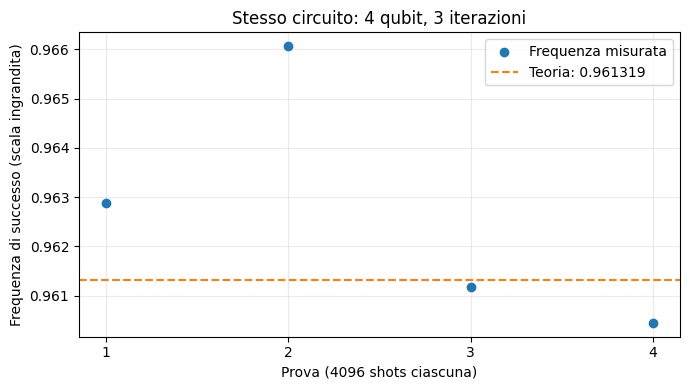

In [82]:
# Il circuito compilato resta fisso; cambia solo il seme del campionamento.
trial_n = 4
trial_k = 3
trial_target = "0001"
trial_shots = 4096
trial_seeds = [RANDOM_SEED + i for i in range(4)]

trial_backend = make_ideal_backend()
trial_circuit = build_grover_circuit(trial_n, [trial_target], trial_k)
trial_compiled = transpile(trial_circuit, trial_backend,
                           optimization_level=IDEAL_OPTIMIZATION_LEVEL,
                           seed_transpiler=RANDOM_SEED)
trial_theory = theoretical_success_probability(2 ** trial_n, 1, trial_k)

trial_rows = []
for trial, seed in enumerate(trial_seeds, start=1):
    counts = trial_backend.run(trial_compiled, shots=trial_shots,
                               seed_simulator=seed).result().get_counts()
    successes = counts.get(trial_target, 0)
    frequency = successes / trial_shots
    trial_rows.append({
        "Prova": trial, "Seed": seed, "Shots": trial_shots, "Successi": successes,
        "Teoria": trial_theory, "Frequenza": frequency,
        "Scarto": frequency - trial_theory,
    })

repeated_trials_df = pd.DataFrame(trial_rows)
display(repeated_trials_df.round(6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(repeated_trials_df["Prova"], repeated_trials_df["Frequenza"],
           label="Frequenza misurata", zorder=3)
ax.axhline(trial_theory, color="tab:orange", linestyle="--",
           label=f"Teoria: {trial_theory:.6f}")
ax.set(xticks=repeated_trials_df["Prova"], xlabel="Prova (4096 shots ciascuna)",
       ylabel="Frequenza di successo (scala ingrandita)",
       title="Stesso circuito: 4 qubit, 3 iterazioni")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## 10. Scaling ideale con la dimensione dello spazio di ricerca
Aumento il numero di qubit da 2 a 7, passando da 4 a 128 stati possibili. Cerco sempre una sola soluzione, `00...01`, con 4096 shot e il numero intero di iterazioni scelto vicino al primo massimo ideale.

Nei grafici confronto due aspetti:
- **Iterazioni e costo del circuito.** La stima $(\pi/4)\sqrt{N}$ riguarda il numero di chiamate all'oracolo. Per capire quanto costa realizzarle, misuro anche profondità e numero di porte dopo la compilazione nella base `u`, `cx`. Una porta multicontrollata viene quindi conteggiata attraverso le porte in cui viene scomposta. In questo test non impongo la connettività di una QPU specifica.
- **Tempo del simulatore.** Registro quanto impiega Aer sul computer locale. Questo valore non misura il tempo di un processore quantistico; con una sola esecuzione per dimensione può risentire delle fluttuazioni del sistema.

,n,N,k_opt,depth,total_gate_count,two_qubit_gate_count,execution_time,theoretical_probability,success_probability,standard_error
0,2,4,1,5,8,2,0.004301,1.0,1.0,0.0
1,3,8,2,45,63,24,0.00514,0.945312,0.944092,0.00359
2,4,16,3,157,178,84,0.0068,0.961319,0.959473,0.003081
3,5,32,4,513,629,288,0.013643,0.999182,0.998779,0.000546
4,6,64,6,1561,2154,1008,0.036535,0.996586,0.996094,0.000975
5,7,128,8,3027,4471,1984,0.050459,0.99562,0.995605,0.001034


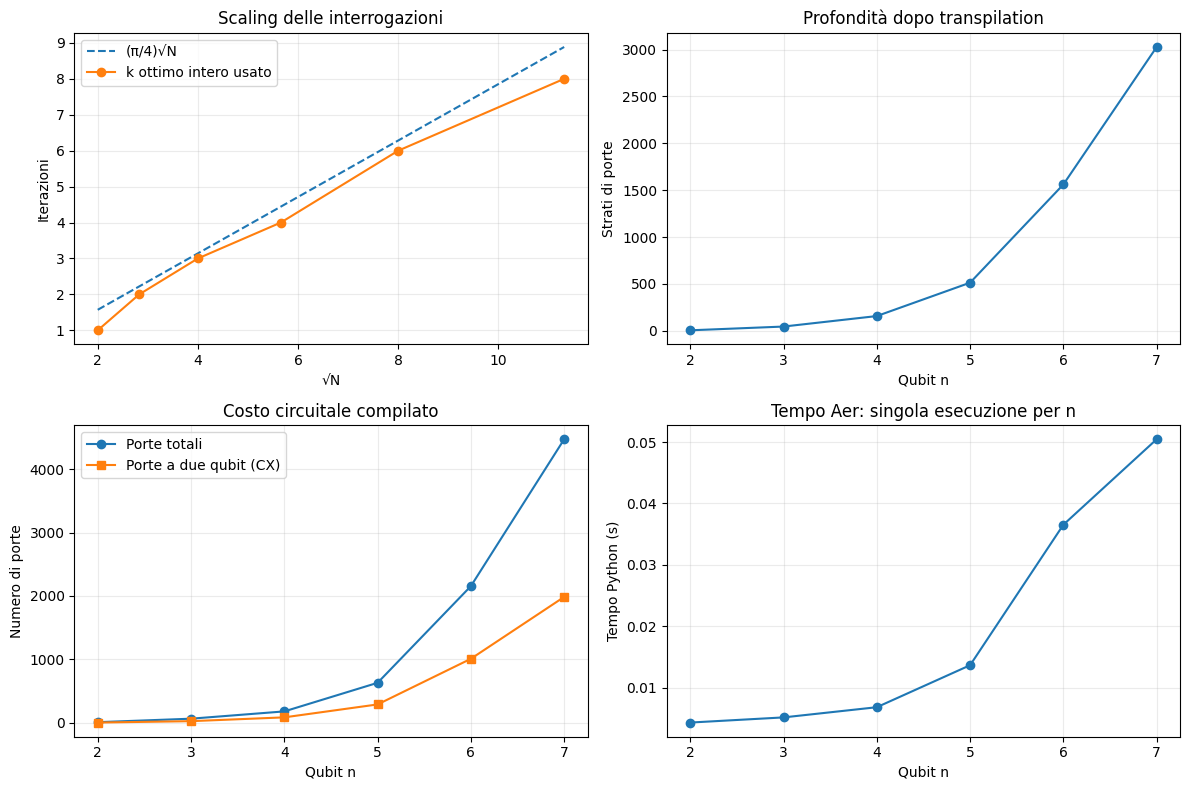

In [83]:
def run_tagged_ideal_experiment(n, marked, k, shots, seed, group):
    """Riusa l'esecuzione ideale e completa i metadati del DataFrame generale."""
    row = run_ideal_experiment(n, marked, k, shots, seed)
    compiled = transpile(build_grover_circuit(n, marked, k, False), make_ideal_backend(seed),
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=seed)
    row.update(p1=0.0, p2=0.0, readout_error=0.0,
               success_probability=row["measured_success_probability"],
               expected_noisy_probability=row["theoretical_probability"],
               actual_basis_gates=",".join(sorted({item.operation.name for item in compiled.data})),
               simulation_method="statevector", experiment_group=group,
               theta=grover_theta(2 ** n, len(marked)),
               k_opt=optimal_grover_iterations(2 ** n, len(marked)))
    return row


# Aggiungo angolo e iterazioni ottimali anche ai risultati precedenti.
RESULT_DTYPES.update({"theta": "Float64", "k_opt": "Int64"})
results_df["theta"] = [grover_theta(int(N), int(M)) for N, M in zip(results_df.N, results_df.M)]
results_df["k_opt"] = [optimal_grover_iterations(int(N), int(M)) for N, M in zip(results_df.N, results_df.M)]
results_df = results_df.astype(RESULT_DTYPES)
scaling_rows = []
for n in range(2, 8):
    k = optimal_grover_iterations(2 ** n, 1)
    scaling_rows.append(run_tagged_ideal_experiment(n, (format(1, f"0{n}b"),), k,
                        SHOTS_DEFAULT, RANDOM_SEED + 100 * n + k, "scaling"))
scaling_df = pd.DataFrame(scaling_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df.experiment_group != "scaling"], scaling_df],
                       ignore_index=True).astype(RESULT_DTYPES)
assert len(scaling_df) == 6 and set(scaling_df.n) == set(range(2, 8))
assert np.all(np.diff(scaling_df.k_opt.to_numpy(dtype=int)) >= 0)
assert (scaling_df.k == scaling_df.k_opt).all()
scaling_summary_df = scaling_df[["n", "N", "k_opt", "depth", "total_gate_count",
    "two_qubit_gate_count", "execution_time", "theoretical_probability", "success_probability", "standard_error"]]
display(scaling_summary_df)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
root_N = np.sqrt(scaling_df.N.to_numpy(dtype=float))
axes[0, 0].plot(root_N, np.pi/4 * root_N, "--", label="(π/4)√N")
axes[0, 0].plot(root_N, scaling_df.k_opt, "o-", label="k ottimo intero usato")
axes[0, 0].set(xlabel="√N", ylabel="Iterazioni", title="Scaling delle interrogazioni")
axes[0, 1].plot(scaling_df.n, scaling_df.depth, "o-")
axes[0, 1].set(xlabel="Qubit n", ylabel="Strati di porte", title="Profondità dopo transpilation")
axes[1, 0].plot(scaling_df.n, scaling_df.total_gate_count, "o-", label="Porte totali")
axes[1, 0].plot(scaling_df.n, scaling_df.two_qubit_gate_count, "s-", label="Porte a due qubit (CX)")
axes[1, 0].set(xlabel="Qubit n", ylabel="Numero di porte", title="Costo circuitale compilato")
axes[1, 1].plot(scaling_df.n, scaling_df.execution_time, "o-")
axes[1, 1].set(xlabel="Qubit n", ylabel="Tempo Python (s)", title="Tempo Aer: singola esecuzione per n")
for ax in axes.flat:
    ax.grid(alpha=.25)
for ax in (axes[0, 0], axes[1, 0]):
    ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

## 11. Ricerca con più soluzioni: 5 qubit, 32 stati
In questo esperimento mantengo **5 qubit**, quindi **32 stati possibili**, e cambio il numero di soluzioni: **1, 2, 4 oppure 8**. Uso una lista fissa di stati, prendendo ogni volta i primi $M$, in modo che i casi siano confrontabili.

Per ogni caso provo **da 0 a 8 iterazioni**, con **4096 shot per circuito**. Una misura conta come successo se restituisce **una qualsiasi delle soluzioni**, non necessariamente una stringa specifica.

Confronto la frequenza misurata con la probabilità teorica:
$$P(k)=\sin^2((2k+1)\theta), \qquad \theta=\arcsin\sqrt{M/32}.$$
Qui $M$ è il numero di soluzioni e $k$ il numero di iterazioni.

**Lettura dei risultati.** Con più soluzioni, in genere servono meno iterazioni per raggiungere il primo massimo. La tabella riporta le iterazioni scelte e confronta teoria e misure; i grafici mostrano come cambia il successo al variare di $k$.

,M,theta,k_opt,theoretical_probability,measured_probability,standard_error
4,1,0.1777,4,0.9992,0.9995,0.0003
12,2,0.2527,3,0.9613,0.9648,0.0029
20,4,0.3614,2,0.9453,0.9429,0.0036
28,8,0.5236,1,1.0,1.0,0.0


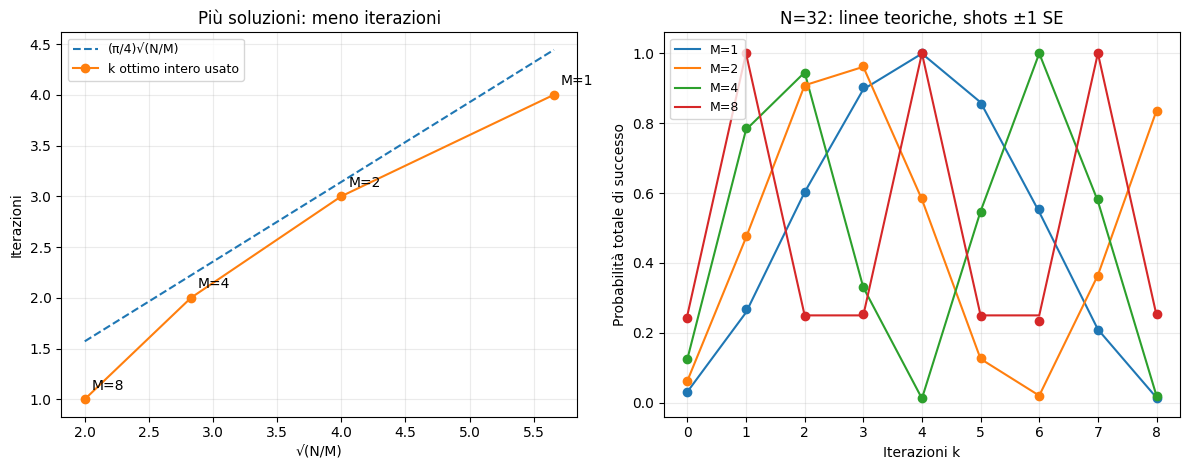

In [84]:
MULTI_N = 5
M_VALUES = (1, 2, 4, 8)

marked_pool = ["00001", "01000", "01111", "10110",
               "11101", "00100", "01011", "10010"]

multi_rows = []
for M in M_VALUES:
    marked = marked_pool[:M]
    for k in range(9):
        seed = RANDOM_SEED + 10000 + 100 * M + k
        result = run_tagged_ideal_experiment(
            MULTI_N, marked, k, SHOTS_DEFAULT, seed, "multiple_solutions"
        )
        multi_rows.append(result)

multiple_solutions_df = pd.DataFrame(multi_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
results_df = pd.concat([
    results_df[results_df.experiment_group != "multiple_solutions"],
    multiple_solutions_df,
], ignore_index=True).astype(RESULT_DTYPES)


multiple_summary_df = multiple_solutions_df[
    multiple_solutions_df.k == multiple_solutions_df.k_opt
][["M", "theta", "k_opt", "theoretical_probability", "success_probability", "standard_error"]]
multiple_summary_df = multiple_summary_df.rename(columns={"success_probability": "measured_probability"})
display(multiple_summary_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
x_values = np.sqrt(32 / multiple_summary_df.M.to_numpy(dtype=float))
order = np.argsort(x_values)
axes[0].plot(x_values[order], np.pi/4 * x_values[order], "--", label="(π/4)√(N/M)")
axes[0].plot(x_values, multiple_summary_df.k_opt, "o-", label="k ottimo intero usato")
for x, row in zip(x_values, multiple_summary_df.itertuples()):
    axes[0].annotate(f"M={row.M}", (x, row.k_opt), xytext=(5, 7), textcoords="offset points")
axes[0].set(xlabel="√(N/M)", ylabel="Iterazioni", title="Più soluzioni: meno iterazioni")
for M, group in multiple_solutions_df.groupby("M"):
    group = group.sort_values("k")
    line, = axes[1].plot(group.k, group.theoretical_probability, label=f"M={M}")
    axes[1].errorbar(group.k.to_numpy(dtype=float), group.success_probability.to_numpy(dtype=float),
                     yerr=group.standard_error.to_numpy(dtype=float), fmt="o", capsize=2, color=line.get_color())
axes[1].set(xlabel="Iterazioni k", ylabel="Probabilità totale di successo",
            title="N=32: linee teoriche, shots ±1 SE", xticks=range(9), ylim=(-.04, 1.06))
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend(fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)

### 11.1 Numero di soluzioni ignoto: ricerca randomizzata
Se non conosco il numero di soluzioni, non posso calcolare quante iterazioni conviene fare. Provo quindi una ricerca con un numero casuale di iterazioni:

1. Scelgo quante iterazioni eseguire tra zero e un limite inizialmente piccolo.
2. Preparo il circuito, applico Grover e simulo la misura di **un candidato**.
3. Controllo se il candidato è una soluzione: se lo è mi fermo; altrimenti aumento il limite e riprovo con un nuovo circuito.

Il limite parte da 1, cresce di un fattore 1,2 e non supera $\sqrt{N}$, con $N=2^n$. La ricerca si ferma dopo al massimo **40 tentativi**: un fallimento non dimostra che non esistano soluzioni.

La funzione riceve l'oracolo e un controllo `is_solution`, ma **non riceve il numero o la lista delle soluzioni**. Questi sono noti solo al test che prepara l'esperimento. Uso `Statevector` per ottenere le probabilità e sorteggiare un singolo esito di misura.

Il codice conserva la storia dei tentativi e conta separatamente le chiamate all'oracolo e le verifiche dei candidati. La sezione 11.2 usa questi dati per confrontare molte ricerche. Il metodo si ispira alla [ricerca randomizzata BBHT](https://arxiv.org/abs/quant-ph/9605034), con un limite aggiunto al numero di tentativi.

In [85]:
def randomized_grover(n, oracle, is_solution, seed, max_attempts=40):
    """Cerca una soluzione senza conoscere quante soluzioni esistono."""
    if max_attempts < 1:
        raise ValueError("Occorre almeno un tentativo.")

    rng = np.random.default_rng(seed)
    N = 2 ** n
    diffuser = build_diffuser(n)
    window = 1.0
    phase_queries = 0
    history = []

    for attempt in range(1, max_attempts + 1):
        # Scelgo uniformemente un intero k con 0 <= k < window.
        k = int(rng.integers(int(np.ceil(window))))

        circuit = QuantumCircuit(n)
        circuit.h(range(n))
        for _ in range(k):
            circuit.compose(oracle, inplace=True)
            circuit.compose(diffuser, inplace=True)

        # Ogni tentativo campiona un solo candidato dalla distribuzione ideale.
        probabilities = Statevector.from_instruction(circuit).probabilities()
        measured = int(rng.choice(N, p=probabilities))
        candidate = format(measured, f"0{n}b")
        found = bool(is_solution(candidate))

        phase_queries += k  # Una chiamata all'oracolo per iterazione.
        history.append({
            "tentativo": attempt, "finestra": window, "k": k,
            "candidato": candidate, "successo": found,
        })
        if found:
            break

        window = min(1.2 * window, np.sqrt(N))

    result = {
        "success": found,
        "candidate": candidate if found else None,
        "attempts": attempt,
        "phase_queries": phase_queries,
        "checks": attempt,
        "total_queries": phase_queries + attempt,
    }
    return result, history


### 11.2 Prove ripetute e costo della ricerca
Eseguo **100 ricerche per ciascun caso**, con 5 qubit e $M=1,2,4,8$. Il numero di soluzioni serve solo a organizzare il test: la ricerca non lo conosce.

La tabella riassume i successi, i tentativi e le chiamate all'oracolo. Riporta anche il costo totale medio e il confronto teorico con una ricerca classica casuale. Le medie includono anche eventuali ricerche fallite al limite di 40 tentativi. Ogni tentativo comprende una verifica classica del candidato, conteggiata separatamente dalle chiamate all'oracolo.

Sotto mostro i passaggi della prima ricerca con una soluzione. I dati completi restano disponibili nei CSV; il grafico rappresenta la somma di chiamate all'oracolo e verifiche.

Costo medio calcolato su tutte le prove, inclusi eventuali fallimenti:


,prove,successi,tentativi_medi,query_fase_medie,query_totali_medie,verifiche_classiche_attese
M,,,,,,
1,100,100,5.23,3.19,8.42,32.0
2,100,100,3.92,1.93,5.85,16.0
4,100,100,2.61,0.92,3.53,8.0
8,100,100,2.38,0.61,2.99,4.0


,M,repetition,tentativo,finestra,k,candidato,successo
0,1,0,1,1.000,0,01001,False
1,1,0,2,1.200,0,00101,False
2,1,0,3,1.440,1,10001,False
3,1,0,4,1.728,0,00100,False
4,1,0,5,2.074,1,00101,False
5,1,0,6,2.488,0,11111,False
6,1,0,7,2.986,2,10011,False
7,1,0,8,3.583,3,00001,True


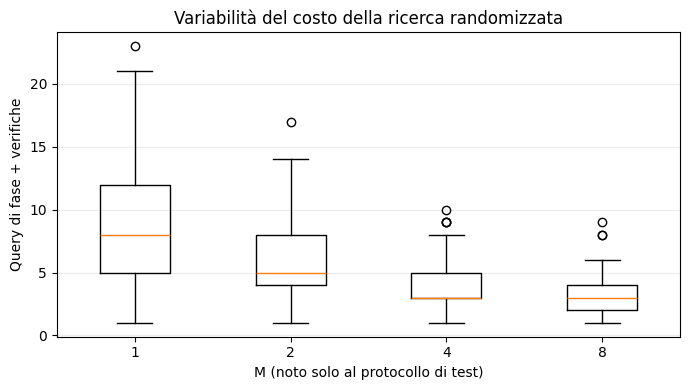

In [86]:
randomized_rows = []
randomized_histories = []
for M in M_VALUES:
    hidden_states = frozenset(marked_pool[:M])
    oracle = build_phase_oracle(MULTI_N, list(marked_pool[:M]))
    for repetition in range(100):
        seed = RANDOM_SEED + 50000 + 1000 * M + repetition
        outcome, history = randomized_grover(MULTI_N, oracle, hidden_states.__contains__, seed)
        randomized_rows.append(dict(M=M, repetition=repetition, seed=seed, **outcome))
        randomized_histories.extend(dict(M=M, repetition=repetition, **step) for step in history)

randomized_results_df = pd.DataFrame(randomized_rows)
randomized_trace_df = pd.DataFrame(randomized_histories)
randomized_summary = randomized_results_df.groupby("M").agg(
    prove=("success", "size"), successi=("success", "sum"),
    tentativi_medi=("attempts", "mean"), query_fase_medie=("phase_queries", "mean"),
    query_totali_medie=("total_queries", "mean"),
)
randomized_summary["verifiche_classiche_attese"] = 2 ** MULTI_N / randomized_summary.index
print("Costo medio calcolato su tutte le prove, inclusi eventuali fallimenti:")
display(randomized_summary.round(2))

# Esempio: la prima ricerca con una sola soluzione.
display(randomized_trace_df.query("M == 1 and repetition == 0").round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([randomized_results_df.loc[randomized_results_df.M == M, "total_queries"]
            for M in M_VALUES], tick_labels=[str(M) for M in M_VALUES])
ax.set(xlabel="M (noto solo al protocollo di test)", ylabel="Query di fase + verifiche",
       title="Variabilità del costo della ricerca randomizzata")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
display(fig)
plt.close(fig)

randomized_directory = Path("results")
randomized_directory.mkdir(exist_ok=True)
randomized_results_df.to_csv(randomized_directory / "grover_randomized_search.csv", index=False)
randomized_trace_df.to_csv(randomized_directory / "grover_randomized_attempts.csv", index=False)
randomized_summary.to_csv(randomized_directory / "grover_randomized_summary.csv")

## 12. Simulazione con un fake backend IBM
Uso **FakeManilaV2**, un profilo salvato di un processore IBM da 5 qubit.
Aer costruisce dai suoi dati un modello approssimato di rumore delle porte,
rilassamento e lettura. Non serve un account IBM: la simulazione avviene in locale.
Non si tratta di una replica esatta o aggiornata del dispositivo reale.

Fisso **4 qubit**, stato cercato `0001` e **4096 shots**. Provo da **0 a 6
iterazioni**, includendo il massimo ideale a 3 iterazioni e il calo successivo.
Il profilo di rumore resta fisso: non scelgo manualmente `p1` e `p2`.

Compilo per la topologia e le porte di Manila, poi eseguiamo **lo stesso circuito
compilato** sia con rumore sia senza. La tabella confronta teoria e frequenze misurate.

Nelle versioni attuali l'import proviene da `qiskit_ibm_runtime.fake_provider`.
[documentazione IBM sui fake backend](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider).


In [87]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

fake_backend = FakeManilaV2()
noisy_sim = AerSimulator.from_backend(fake_backend)
noisy_sim.set_options(method="density_matrix", max_parallel_threads=1)
ideal_sim = AerSimulator(method="statevector")
print("Profilo:", fake_backend.name, "| Qubit disponibili:", fake_backend.num_qubits)
print("Data del profilo:", fake_backend.properties().last_update_date)

RESULT_DTYPES.update({"compiled_ideal_frequency": "Float64",
                      "calibration_date": "string", "runtime_version": "string"})


def run_noisy_experiment(n_qubits, marked_states, iterations, shots, seed,
                         backend_profile=None, simulator=None):
    """Confronta lo stesso circuito con e senza rumore del profilo scelto."""
    backend_profile = fake_backend if backend_profile is None else backend_profile
    simulator = noisy_sim if simulator is None else simulator
    circuit = build_grover_circuit(n_qubits, marked_states, iterations)
    compiled = transpile(circuit, backend_profile, optimization_level=1,
                         seed_transpiler=RANDOM_SEED)

    start = perf_counter()
    counts = simulator.run(compiled, shots=shots, seed_simulator=seed).result().get_counts()
    elapsed = perf_counter() - start
    ideal_counts = ideal_sim.run(compiled, shots=shots, seed_simulator=seed).result().get_counts()
    measured = sum(counts.get(state, 0) for state in marked_states) / shots
    ideal_frequency = sum(ideal_counts.get(state, 0) for state in marked_states) / shots

    gates = compiled.remove_final_measurements(inplace=False)
    return {
        "backend": backend_profile.name, "mode": "noisy", "n": n_qubits,
        "N": 2 ** n_qubits, "M": len(marked_states), "marked_states": tuple(marked_states),
        "k": iterations, "shots": shots,
        "theoretical_probability": theoretical_success_probability(2 ** n_qubits, len(marked_states), iterations),
        "measured_success_probability": measured, "success_probability": measured,
        "compiled_ideal_frequency": ideal_frequency,
        "standard_error": float(np.sqrt(measured * (1 - measured) / shots)),
        "execution_time": elapsed, "depth": gates.depth(), "total_gate_count": len(gates.data),
        "two_qubit_gate_count": sum(item.operation.num_qubits == 2 for item in gates.data),
        "seed": seed, "seed_transpiler": RANDOM_SEED, "optimization_level": 1,
        "basis_gates": tuple(simulator.configuration().basis_gates),
        "actual_basis_gates": ",".join(sorted({item.operation.name for item in gates.data})),
        "counts": dict(counts), "normalized_counts": {state: count / shots for state, count in counts.items()},
        "qiskit_version": LIBRARY_VERSIONS["qiskit"], "qiskit_aer_version": LIBRARY_VERSIONS["qiskit-aer"],
        "simulation_method": "density_matrix", "experiment_group": "fake_backend",
        "calibration_date": backend_profile.properties().last_update_date.isoformat(),
        "runtime_version": version("qiskit-ibm-runtime"),
    }


Profilo: fake_manila | Qubit disponibili: 5
Data del profilo: 2024-05-27 15:27:23-03:00


In [88]:
noisy_rows = [run_noisy_experiment(4, ["0001"], k, SHOTS_DEFAULT, RANDOM_SEED + k)
              for k in range(7)]
noisy_results_df = pd.DataFrame(noisy_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
manila_results_df = noisy_results_df.copy()
results_df = pd.concat([results_df.loc[results_df["mode"] != "noisy"], noisy_results_df], ignore_index=True).astype(RESULT_DTYPES)
fake_summary = noisy_results_df[["k", "shots", "theoretical_probability",
                                 "compiled_ideal_frequency", "success_probability"]].copy()
fake_summary.columns = ["Iterazioni", "Shots", "Teoria ideale", "Frequenza ideale", "Frequenza con rumore"]
display(fake_summary.round(4))


,Iterazioni,Shots,Teoria ideale,Frequenza ideale,Frequenza con rumore
0,0,4096,0.0625,0.0635,0.0637
1,1,4096,0.4727,0.481,0.2205
2,2,4096,0.9084,0.9158,0.2246
3,3,4096,0.9613,0.9619,0.1448
4,4,4096,0.5817,0.5815,0.0952
5,5,4096,0.1255,0.1355,0.0718
6,6,4096,0.0204,0.0173,0.0535


### 12.1 Grafici dei risultati
A sinistra confronto teoria, frequenze ideali e frequenze con il rumore di Manila.
Le barre sul caso rumoroso indicano un errore standard stimato.
A destra mostro la distribuzione degli esiti con rumore per **3 iterazioni**:
la barra arancione corrisponde alla soluzione `0001`.


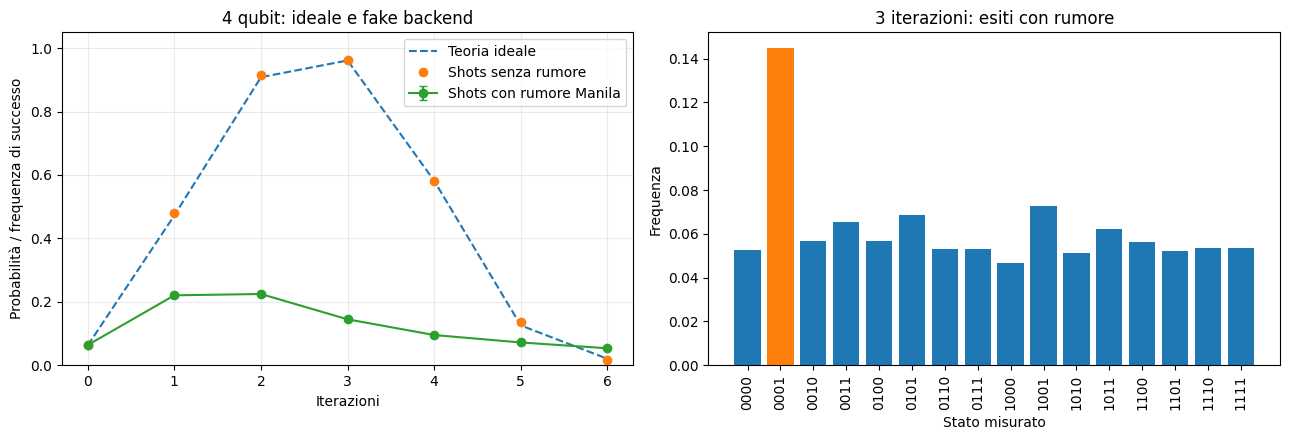

Miglior k misurato tra 0 e 6: 2; frequenza: 0.2246
Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.


In [89]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(manila_results_df.k, manila_results_df.theoretical_probability, "--", label="Teoria ideale")
axes[0].plot(manila_results_df.k, manila_results_df.compiled_ideal_frequency, "o", label="Shots senza rumore")
axes[0].errorbar(manila_results_df.k.to_numpy(dtype=float), manila_results_df.success_probability.to_numpy(dtype=float),
                 yerr=manila_results_df.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3,
                 label="Shots con rumore Manila")
axes[0].set(xlabel="Iterazioni", ylabel="Probabilità / frequenza di successo",
            title="4 qubit: ideale e fake backend", xticks=range(7), ylim=(0, 1.05))
axes[0].legend()
axes[0].grid(alpha=0.25)

example = manila_results_df[manila_results_df.k == 3].iloc[0]
states = [format(i, "04b") for i in range(16)]
frequencies = [example["normalized_counts"].get(state, 0) for state in states]
axes[1].bar(states, frequencies, color=["tab:orange" if state == "0001" else "tab:blue" for state in states])
axes[1].set(title="3 iterazioni: esiti con rumore", xlabel="Stato misurato", ylabel="Frequenza")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
display(fig)
plt.close(fig)

best_fake = manila_results_df.sort_values(["success_probability", "k"], ascending=[False, True]).iloc[0]
print(f"Miglior k misurato tra 0 e 6: {int(best_fake.k)}; frequenza: {best_fake.success_probability:.4f}")
print("Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.")


### 12.2 Interpretazione
Confronto il successo ideale con quello del fake backend: gli errori di porte
e lettura possono ridurre la concentrazione delle misure sulla soluzione.
Aumentare le iterazioni aggiunge porte e quindi esposizione al rumore;
il massimo misurato può spostarsi rispetto a quello ideale.

I risultati dipendono dal profilo salvato, dalla compilazione e dagli shots.
Non sono misure su hardware reale e non prevedono esattamente le prestazioni attuali di Manila.


### 12.3 Stesso esperimento con FakeNairobiV2
Ripeto le sette prove con **FakeNairobiV2**, un profilo IBM da **7 qubit**.
Il problema resta identico: **4 qubit logici**, stato `0001`, da **0 a 6 iterazioni**
e **4096 shots**. Il circuito viene compilato per le porte e i collegamenti di Nairobi.

Confronto lo stesso circuito compilato con e senza rumore. Come per Manila,
il grafico a sinistra mostra il successo e quello a destra gli esiti a 3 iterazioni.
La tabella finale affianca le frequenze rumorose dei due profili.
Le differenze riflettono sia i dati di calibrazione salvati sia la compilazione
sulle rispettive topologie: non sono una classifica delle prestazioni attuali dei dispositivi.


In [90]:
from qiskit_ibm_runtime.fake_provider import FakeNairobiV2

nairobi_backend = FakeNairobiV2()
nairobi_sim = AerSimulator.from_backend(nairobi_backend)
nairobi_sim.set_options(method="density_matrix", max_parallel_threads=1)
print("Profilo:", nairobi_backend.name, "| Qubit disponibili:", nairobi_backend.num_qubits)
print("Data del profilo:", nairobi_backend.properties().last_update_date)

nairobi_rows = [run_noisy_experiment(4, ["0001"], k, SHOTS_DEFAULT, RANDOM_SEED + k,
                                     backend_profile=nairobi_backend, simulator=nairobi_sim)
                for k in range(7)]
nairobi_results_df = pd.DataFrame(nairobi_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
nairobi_summary = nairobi_results_df[["k", "shots", "theoretical_probability",
                                    "compiled_ideal_frequency", "success_probability"]].copy()
nairobi_summary.columns = ["Iterazioni", "Shots", "Teoria ideale", "Frequenza ideale", "Frequenza con rumore"]
display(nairobi_summary.round(4))

# Sostituisco i risultati rumorosi precedenti per evitare duplicati.
noisy_results_df = pd.concat([manila_results_df, nairobi_results_df], ignore_index=True).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df["mode"] != "noisy"], noisy_results_df],
                       ignore_index=True).astype(RESULT_DTYPES)


Profilo: fake_nairobi | Qubit disponibili: 7
Data del profilo: 2024-05-27 15:45:40-03:00


,Iterazioni,Shots,Teoria ideale,Frequenza ideale,Frequenza con rumore
0,0,4096,0.0625,0.0635,0.0635
1,1,4096,0.4727,0.4885,0.3081
2,2,4096,0.9084,0.9097,0.4038
3,3,4096,0.9613,0.9604,0.3057
4,4,4096,0.5817,0.5757,0.1777
5,5,4096,0.1255,0.1226,0.0886
6,6,4096,0.0204,0.0171,0.0693


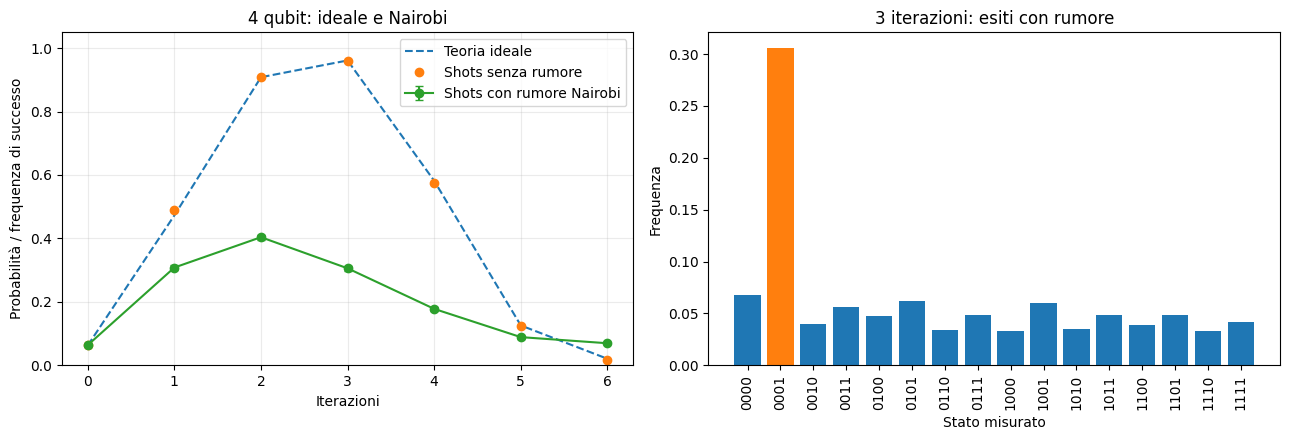

Miglior k misurato tra 0 e 6: 2; frequenza: 0.4038
Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.
Confronto delle frequenze con rumore, a parita' di problema e shots:


backend,fake_manila,fake_nairobi
Iterazioni,,
0,0.0637,0.0635
1,0.2205,0.3081
2,0.2246,0.4038
3,0.1448,0.3057
4,0.0952,0.1777
5,0.0718,0.0886
6,0.0535,0.0693


In [91]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(nairobi_results_df.k, nairobi_results_df.theoretical_probability, "--", label="Teoria ideale")
axes[0].plot(nairobi_results_df.k, nairobi_results_df.compiled_ideal_frequency, "o", label="Shots senza rumore")
axes[0].errorbar(nairobi_results_df.k.to_numpy(dtype=float), nairobi_results_df.success_probability.to_numpy(dtype=float),
                 yerr=nairobi_results_df.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3,
                 label="Shots con rumore Nairobi")
axes[0].set(xlabel="Iterazioni", ylabel="Probabilità / frequenza di successo",
            title="4 qubit: ideale e Nairobi", xticks=range(7), ylim=(0, 1.05))
axes[0].legend()
axes[0].grid(alpha=0.25)

nairobi_example = nairobi_results_df[nairobi_results_df.k == 3].iloc[0]
states = [format(i, "04b") for i in range(16)]
frequencies = [nairobi_example["normalized_counts"].get(state, 0) for state in states]
axes[1].bar(states, frequencies, color=["tab:orange" if state == "0001" else "tab:blue" for state in states])
axes[1].set(title="3 iterazioni: esiti con rumore", xlabel="Stato misurato", ylabel="Frequenza")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
display(fig)
plt.close(fig)

best_nairobi = nairobi_results_df.sort_values(["success_probability", "k"], ascending=[False, True]).iloc[0]
print(f"Miglior k misurato tra 0 e 6: {int(best_nairobi.k)}; frequenza: {best_nairobi.success_probability:.4f}")
print("Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.")

print("Confronto delle frequenze con rumore, a parita' di problema e shots:")
backend_comparison = noisy_results_df.pivot(index="k", columns="backend", values="success_probability")
backend_comparison.index.name = "Iterazioni"
display(backend_comparison.round(4))


### 12.4 Stesso esperimento con FakeMumbaiV2
Ripeto le prove con **FakeMumbaiV2**, un profilo IBM da **27 qubit**.
Il problema resta di **4 qubit logici**, con stato cercato `0001`, da **0 a 6
iterazioni** e **4096 shots** per prova. Compilo per la topologia di Mumbai
e confronto lo stesso circuito con e senza il suo rumore.

Aer esclude dalla simulazione i qubit inutilizzati; i qubit eventualmente
coinvolti nello spostamento degli stati durante la compilazione restano inclusi.
Tabella e grafici seguono lo stesso formato dei precedenti sottocapitoli.
La tabella finale confronta **Manila, Nairobi e Mumbai**: sono profili salvati,
non misure delle prestazioni attuali dei dispositivi reali.


In [92]:
from qiskit_ibm_runtime.fake_provider import FakeMumbaiV2

mumbai_backend = FakeMumbaiV2()
mumbai_sim = AerSimulator.from_backend(mumbai_backend)
mumbai_sim.set_options(method="density_matrix", max_parallel_threads=1,
                       enable_truncation=True, max_memory_mb=2048)
print("Profilo:", mumbai_backend.name, "| Qubit disponibili:", mumbai_backend.num_qubits)
print("Data del profilo:", mumbai_backend.properties().last_update_date)

mumbai_rows = [run_noisy_experiment(4, ["0001"], k, SHOTS_DEFAULT, RANDOM_SEED + k,
                                     backend_profile=mumbai_backend, simulator=mumbai_sim)
                for k in range(7)]
mumbai_results_df = pd.DataFrame(mumbai_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
mumbai_summary = mumbai_results_df[["k", "shots", "theoretical_probability",
                                    "compiled_ideal_frequency", "success_probability"]].copy()
mumbai_summary.columns = ["Iterazioni", "Shots", "Teoria ideale", "Frequenza ideale", "Frequenza con rumore"]
display(mumbai_summary.round(4))

# Sostituisco i risultati rumorosi precedenti con quelli dei tre profili.
noisy_results_df = pd.concat([manila_results_df, nairobi_results_df, mumbai_results_df], ignore_index=True).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df["mode"] != "noisy"], noisy_results_df],
                       ignore_index=True).astype(RESULT_DTYPES)


Profilo: fake_mumbai | Qubit disponibili: 27
Data del profilo: 2021-03-13 10:58:26-05:00


,Iterazioni,Shots,Teoria ideale,Frequenza ideale,Frequenza con rumore
0,0,4096,0.0625,0.0635,0.0637
1,1,4096,0.4727,0.4714,0.3127
2,2,4096,0.9084,0.9158,0.4082
3,3,4096,0.9613,0.967,0.3027
4,4,4096,0.5817,0.5815,0.1621
5,5,4096,0.1255,0.1355,0.0872
6,6,4096,0.0204,0.0173,0.0635


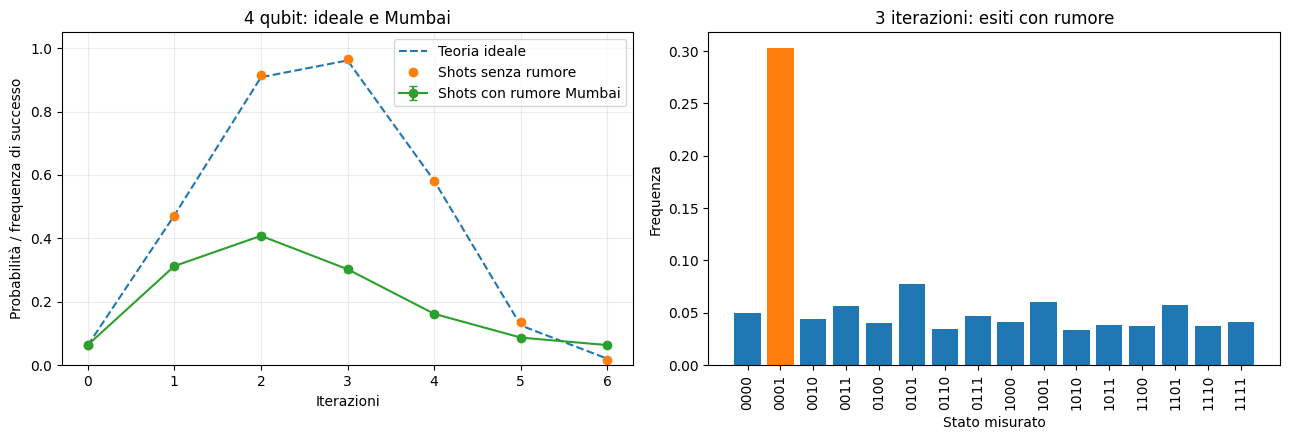

Miglior k misurato tra 0 e 6: 2; frequenza: 0.4082
Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.
Confronto delle frequenze con rumore, a parita' di problema e shots:


backend,fake_manila,fake_mumbai,fake_nairobi
Iterazioni,,,
0,0.0637,0.0637,0.0635
1,0.2205,0.3127,0.3081
2,0.2246,0.4082,0.4038
3,0.1448,0.3027,0.3057
4,0.0952,0.1621,0.1777
5,0.0718,0.0872,0.0886
6,0.0535,0.0635,0.0693


In [93]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(mumbai_results_df.k, mumbai_results_df.theoretical_probability, "--", label="Teoria ideale")
axes[0].plot(mumbai_results_df.k, mumbai_results_df.compiled_ideal_frequency, "o", label="Shots senza rumore")
axes[0].errorbar(mumbai_results_df.k.to_numpy(dtype=float), mumbai_results_df.success_probability.to_numpy(dtype=float),
                 yerr=mumbai_results_df.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3,
                 label="Shots con rumore Mumbai")
axes[0].set(xlabel="Iterazioni", ylabel="Probabilità / frequenza di successo",
            title="4 qubit: ideale e Mumbai", xticks=range(7), ylim=(0, 1.05))
axes[0].legend()
axes[0].grid(alpha=0.25)

mumbai_example = mumbai_results_df[mumbai_results_df.k == 3].iloc[0]
states = [format(i, "04b") for i in range(16)]
frequencies = [mumbai_example["normalized_counts"].get(state, 0) for state in states]
axes[1].bar(states, frequencies, color=["tab:orange" if state == "0001" else "tab:blue" for state in states])
axes[1].set(title="3 iterazioni: esiti con rumore", xlabel="Stato misurato", ylabel="Frequenza")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
display(fig)
plt.close(fig)

best_mumbai = mumbai_results_df.sort_values(["success_probability", "k"], ascending=[False, True]).iloc[0]
print(f"Miglior k misurato tra 0 e 6: {int(best_mumbai.k)}; frequenza: {best_mumbai.success_probability:.4f}")
print("Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.")

print("Confronto delle frequenze con rumore, a parita' di problema e shots:")
backend_comparison = noisy_results_df.pivot(index="k", columns="backend", values="success_probability")
backend_comparison.index.name = "Iterazioni"
display(backend_comparison.round(4))


I risultati mostrano come il rumore riduca il successo rispetto al caso ideale.

- **Picco anticipato:** il massimo osservato nei tre profili si trova a 2 iterazioni, mentre quello ideale è a 3. In queste prove, aggiungere la terza iterazione peggiora il risultato.
- **Manila:** raggiunge circa il 22,46%, molto vicino al 22,05% con una sola iterazione. La piccola differenza va considerata insieme alle fluttuazioni statistiche.
- **Mumbai e Nairobi:** raggiungono circa il 40,82% e il 40,38%. Le differenze dipendono dai profili di rumore e dai circuiti compilati; da questi grafici non posso attribuirle soltanto alle porte SWAP o ai tempi di coerenza.
- **Iterazioni successive:** il successo diminuisce e, verso la fine della scansione, si avvicina al valore uniforme $1/16$. Anche la probabilità ideale oscilla: il calo non va attribuito interamente al rumore.

Si tratta di simulazioni con profili salvati, non di misure sulle QPU reali.

## 13. Grover su hardware IBM reale
Dopo le simulazioni ideali e con rumore, passo all'esecuzione su un dispositivo
IBM reale. Ho effettuato una prima prova con 4 qubit su `ibm_fez`; ora estendo
l'esperimento a **2, 3, 4 e 5 qubit**, per osservare come cambia il successo
all'aumentare della dimensione del circuito.

Per ogni caso considero una sola soluzione, `00...01`, e scelgo il numero
ottimo di iterazioni ideale: rispettivamente **1, 2, 3 e 4**. Uso **1024 shots
per circuito**. Raccolgo i quattro circuiti in un solo job sullo stesso backend,
così da rendere il confronto più omogeneo. Questo non elimina le differenze
di layout e di profondità introdotte dalla compilazione.
La nuova prova a 4 qubit non sostituisce quella precedente.

### 13.1 Accesso alla piattaforma
Per riprodurre l'esperimento occorrono un account IBM Quantum Platform,
un'istanza Open Plan e il pacchetto `qiskit-ibm-runtime` del kernel `.venv`.
Dalla dashboard si crea una **API key**; nella pagina **Instances** si copia
il **CRN** dell'istanza da utilizzare.

La cella seguente salva l'account localmente con il nome `grover-open`.
La eseguo con `CONFIGURE_IBM_ACCOUNT=True` soltanto alla prima configurazione,
inserendo la chiave nel campo nascosto e il CRN nel campo successivo.
Successivamente lascio il flag a `False`. La chiave non viene scritta nel notebook.

[credenziali](https://quantum.cloud.ibm.com/docs/en/guides/save-credentials),
[Open Plan](https://quantum.cloud.ibm.com/docs/en/guides/plans-overview),
[tempo QPU](https://quantum.cloud.ibm.com/docs/en/guides/max-execution-time).


In [94]:
from getpass import getpass
from pathlib import Path
import json
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

CONFIGURE_IBM_ACCOUNT = False  # True abilita la configurazione locale dell'account.
ACCOUNT_NAME = "grover-open"

if CONFIGURE_IBM_ACCOUNT:
    # Il token non appare nel codice o nell'output del notebook.
    api_key = getpass("API key IBM: ")
    instance_crn = input("CRN dell'istanza Open Plan: ").strip()
    try:
        if not api_key or not instance_crn:
            raise ValueError("Servono API key e CRN dell'istanza.")
        QiskitRuntimeService.save_account(
            channel="ibm_quantum_platform", token=api_key, instance=instance_crn,
            name=ACCOUNT_NAME, overwrite=True,
        )
        print("Account salvato. Riporta CONFIGURE_IBM_ACCOUNT a False.")
    finally:
        del api_key

### 13.2 Preparazione dei quattro circuiti
Riutilizzo le funzioni delle sezioni 7 e 8: prima di questa sezione devono quindi
essere state eseguite le celle che definiscono l'oracolo, il diffusore e Grover.
La tabella riassume il piano sperimentale e la probabilità ideale attesa.
Questa preparazione avviene interamente sul computer locale.


In [95]:
HARDWARE_N_VALUES = (2, 3, 4, 5)
HARDWARE_SHOTS = 1024  # Per ciascun circuito: 4096 misure complessive.
hardware_circuits = []
hardware_plan = []

for n in HARDWARE_N_VALUES:
    marked = [format(1, f"0{n}b")]
    k = optimal_grover_iterations(2 ** n, 1)
    circuit = build_grover_circuit(n, marked, k)
    hardware_circuits.append(circuit)
    hardware_plan.append({
        "pub_index": len(hardware_plan), "n": n, "k": k,
        "shots": HARDWARE_SHOTS, "marked_states": marked,
        "theoretical_probability": theoretical_success_probability(2 ** n, 1, k),
        "register_name": circuit.cregs[0].name,
    })
display(pd.DataFrame(hardware_plan)[["n", "k", "marked_states", "shots", "theoretical_probability"]])


,n,k,marked_states,shots,theoretical_probability
0,2,1,[01],1024,1.000000
1,3,2,[001],1024,0.945312
2,4,3,[0001],1024,0.961319
3,5,4,[00001],1024,0.999182


Per collegarmi all'account salvato imposto `CONNECT_IBM=True`.
Scelgo con `least_busy` un backend reale operativo che possa ospitare tutti
i circuiti e li compilo per il suo target. Infine registro profondità e porte a due qubit per interpretare successivamente l'aumento delle risorse richieste.


In [96]:
CONNECT_IBM = True
hardware_service = None
hardware_backend = None
circuits_isa = None

if CONNECT_IBM:
    hardware_service = QiskitRuntimeService(name=ACCOUNT_NAME)
    hardware_backend = hardware_service.least_busy(
        operational=True, simulator=False, min_num_qubits=max(HARDWARE_N_VALUES),
    )
    pm = generate_preset_pass_manager(target=hardware_backend.target,
                                      optimization_level=3, seed_transpiler=RANDOM_SEED)
    circuits_isa = pm.run(hardware_circuits)
    for record, circuit in zip(hardware_plan, circuits_isa):
        gates = circuit.remove_final_measurements(inplace=False)
        record["depth"] = gates.depth()
        record["two_qubit_gates"] = sum(item.operation.num_qubits == 2 for item in gates.data)
    print("Backend:", hardware_backend.name)
    display(pd.DataFrame(hardware_plan)[["n", "k", "depth", "two_qubit_gates"]])
else:
    print("Connessione disattivata: impostare CONNECT_IBM=True per preparare l'esecuzione reale.")


Backend: ibm_fez


,n,k,depth,two_qubit_gates
0,2,1,8,2
1,3,2,142,39
2,4,3,501,165
3,5,4,1405,501


### 13.3 Invio e recupero del job
L'invio avviene soltanto impostando `SUBMIT_HARDWARE=True`: questo passaggio
usa la quota hardware. Dopo l'invio riporto il flag a `False`.
Salvo subito ID e piano sperimentale in `results/hardware_grover_2to5q_job.json`.
Se il file esiste, recupero il job registrato senza ripetere l'invio.
Per una nuova serie uso un nuovo nome per il file che registra il job.


In [97]:
SUBMIT_HARDWARE = True  # True abilita l'invio di un nuovo job, se non è già registrato.
HARDWARE_JOB_FILE = Path("results/hardware_grover_2to5q_job.json")
hardware_job = None
hardware_record = None

if hardware_service is None:
    print("Eseguire prima la connessione del punto 13.2.")
elif HARDWARE_JOB_FILE.exists():
    hardware_record = json.loads(HARDWARE_JOB_FILE.read_text(encoding="utf-8"))
    hardware_job = hardware_service.job(hardware_record["job_id"])
    print("Job recuperato:", hardware_job.job_id(), "| Backend:", hardware_record["backend"])
    display(pd.DataFrame(hardware_record["experiments"]))
elif SUBMIT_HARDWARE:
    if circuits_isa is None:
        raise RuntimeError("Compilare prima i circuiti del punto 13.2.")
    HARDWARE_JOB_FILE.parent.mkdir(parents=True, exist_ok=True)
    sampler = SamplerV2(mode=hardware_backend)
    sampler.options.max_execution_time = 60
    sampler.options.environment.job_tags = ["grover-scaling-2to5"]
    hardware_job = sampler.run(circuits_isa, shots=HARDWARE_SHOTS)
    print("Job inviato:", hardware_job.job_id())
    hardware_record = {"job_id": hardware_job.job_id(), "backend": hardware_backend.name,
                       "experiments": hardware_plan}
    HARDWARE_JOB_FILE.write_text(json.dumps(hardware_record, indent=2), encoding="utf-8")
else:
    print("Invio disattivato: impostare SUBMIT_HARDWARE=True per eseguire la serie.")


Job recuperato: dapjjhcak42c73cin2d0 | Backend: ibm_fez


,pub_index,n,k,shots,marked_states,theoretical_probability,register_name,depth,two_qubit_gates
0,0,2,1,1024,[01],1.000000,c,8,2
1,1,3,2,1024,[001],0.945312,c,142,39
2,2,4,3,1024,[0001],0.961319,c,496,165
3,3,5,4,1024,[00001],0.999182,c,1405,501


### 13.4 Risultati e confronto tra le dimensioni
La cella seguente attende la fine della coda e dell'esecuzione, poi salva
conteggi e riepilogo di ciascun circuito in file JSON e CSV distinti,
identificati dall'ID del job e dall'indice del circuito al suo interno (PUB). Produce inoltre un grafico del
successo e delle risorse compilate al variare dei qubit.

Job: dapjjhcak42c73cin2d0 | Stato: DONE
Attendo la conclusione e salvo i risultati dei quattro circuiti.


,backend,n,k,shots,theoretical_probability,success_probability,depth,two_qubit_gates
0,ibm_fez,2,1,1024,1.000000,0.958984,8,2
1,ibm_fez,3,2,1024,0.945312,0.819336,142,39
2,ibm_fez,4,3,1024,0.961319,0.394531,496,165
3,ibm_fez,5,4,1024,0.999182,0.074219,1405,501


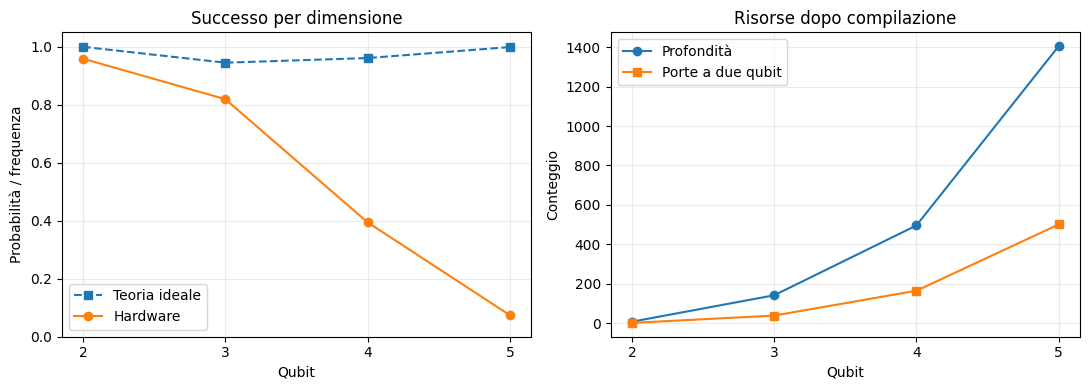

Salvati JSON e CSV per circuito; grafico: C:\Users\pier2\Documents\GitHub\QuantumComputing\results\hardware_dapjjhcak42c73cin2d0_scaling.png
Secondi QPU dell'intero job: non ancora disponibili


In [98]:
hardware_results_df = pd.DataFrame()
if hardware_job is None:
    print("Nessun job caricato: completare il punto 13.3.")
else:
    print("Job:", hardware_job.job_id(), "| Stato:", hardware_job.status(), flush=True)
    print("Attendo la conclusione e salvo i risultati dei quattro circuiti.", flush=True)
    job_result = hardware_job.result()  # Recupero il risultato del job esistente senza inviare nuovi circuiti.
    records = hardware_record["experiments"]
    if len(job_result) != len(records):
        raise ValueError("Numero di risultati diverso dal piano salvato.")
    rows = []
    for record in records:
        pub = job_result[record["pub_index"]]
        counts = getattr(pub.data, record["register_name"]).get_counts()
        shots = sum(counts.values())
        if shots <= 0:
            raise ValueError("Il circuito non ha restituito misure valide.")
        successes = sum(counts.get(state, 0) for state in record["marked_states"])
        row = dict(record, job_id=hardware_record["job_id"], backend=hardware_record["backend"],
                   shots=shots, success_probability=successes / shots)
        rows.append(row)
        destination = Path("results") / f"hardware_{row['job_id']}_pub{row['pub_index']}"
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.with_suffix(".json").write_text(
            json.dumps({"experiment": row, "counts": counts}, indent=2), encoding="utf-8")
        pd.DataFrame([row]).to_csv(destination.with_suffix(".csv"), index=False)

    hardware_results_df = pd.DataFrame(rows).sort_values("n")
    display(hardware_results_df[["backend", "n", "k", "shots", "theoretical_probability",
                                 "success_probability", "depth", "two_qubit_gates"]])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(hardware_results_df.n, hardware_results_df.theoretical_probability, "s--", label="Teoria ideale")
    axes[0].plot(hardware_results_df.n, hardware_results_df.success_probability, "o-", label="Hardware")
    axes[0].set(xlabel="Qubit", ylabel="Probabilità / frequenza", ylim=(0, 1.05), title="Successo per dimensione")
    axes[1].plot(hardware_results_df.n, hardware_results_df.depth, "o-", label="Profondità")
    axes[1].plot(hardware_results_df.n, hardware_results_df.two_qubit_gates, "s-", label="Porte a due qubit")
    axes[1].set(xlabel="Qubit", ylabel="Conteggio", title="Risorse dopo compilazione")
    for ax in axes:
        ax.set_xticks(hardware_results_df.n)
        ax.grid(alpha=0.25)
        ax.legend()
    fig.tight_layout()
    figure_path = Path("results") / f"hardware_{hardware_record['job_id']}_scaling.png"
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print("Salvati JSON e CSV per circuito; grafico:", figure_path.resolve())
    try:
        usage = hardware_job.metrics().get("usage", {})
        print("Secondi QPU dell'intero job:", usage.get("quantum_seconds", "non ancora disponibili"))
    except Exception:
        print("Metriche non disponibili: consultare Workloads.")


## 14. Sintesi dei risultati e conclusioni
In questa sezione raccolgo i risultati più importanti degli esperimenti precedenti.
L'obiettivo è capire che cosa funziona nel caso ideale, che cosa cambia con il
rumore e quanto di questo comportamento ritrovo sull'hardware reale.

### 14.1 Che cosa mostra il caso ideale
Le verifiche con Statevector confermano la formula teorica di Grover.
La probabilità cresce fino al primo massimo, poi diminuisce: quindi
**fare più iterazioni non significa ottenere un risultato migliore**.

Le quattro prove con 4 qubit e 3 iterazioni mostrano piccole differenze nelle
frequenze, anche senza rumore. Sono fluttuazioni dovute al numero finito di shots.
Nello studio dello scaling il numero di iterazioni segue l'andamento atteso
in $\sqrt{N}$, ma anche il circuito compilato diventa più costoso.
Infine, con 5 qubit e 1, 2, 4 o 8 soluzioni, le iterazioni ottime passano da
**4 a 3, 2 e 1**: trovare una soluzione diventa più facile quando ce ne sono di più.

In [99]:
print("4 qubit, 3 iterazioni: teoria =", round(trial_theory, 6))
display(repeated_trials_df[["Prova", "Frequenza", "Scarto"]].round(6))

solutions_summary = multiple_summary_df[["M", "k_opt", "theoretical_probability", "measured_probability"]].copy()
solutions_summary.columns = ["Soluzioni", "Iterazioni ottime", "Teoria", "Frequenza misurata"]
display(solutions_summary.round(4))

4 qubit, 3 iterazioni: teoria = 0.961319


,Prova,Frequenza,Scarto
0,1,0.962891,0.001572
1,2,0.966064,0.004745
2,3,0.961182,-0.000137
3,4,0.960449,-0.000870


,Soluzioni,Iterazioni ottime,Teoria,Frequenza misurata
4,1,4,0.9992,0.9995
12,2,3,0.9613,0.9648
20,4,2,0.9453,0.9429
28,8,1,1.0,1.0


### 14.2 Che cosa cambia con il rumore
Nei tre fake backend il successo diminuisce rispetto alla simulazione ideale.
La tabella confronta il risultato a **3 iterazioni**, ottime nel caso ideale,
con il miglior risultato osservato nella scansione da 0 a 6 iterazioni.

In queste prove il massimo rumoroso arriva a **2 iterazioni**: fermarsi prima
limita il numero di porte soggette a errore. Questo suggerisce che il numero
ottimo ideale non sia necessariamente il migliore in presenza di rumore.
È però un massimo osservato in una sola serie, non una garanzia generale.

In [100]:
# Una sola riga per fake backend, sullo stesso problema a 4 qubit.
noise_summary_rows = []
for backend, group in noisy_results_df.groupby("backend"):
    best = group.sort_values(["success_probability", "k"], ascending=[False, True]).iloc[0]
    at_three = group[group.k == 3].iloc[0]
    noise_summary_rows.append({
        "Profilo": backend, "Successo a k=3": at_three.success_probability,
        "Miglior k osservato": int(best.k), "Successo al miglior k": best.success_probability,
    })
noise_summary = pd.DataFrame(noise_summary_rows)
display(noise_summary.round(4))

,Profilo,Successo a k=3,Miglior k osservato,Successo al miglior k
0,fake_manila,0.1448,2,0.2246
1,fake_mumbai,0.3027,2,0.4082
2,fake_nairobi,0.3057,2,0.4038


### 14.3 Risultati hardware e conclusione
Leggo i risultati reali dai file salvati, senza connettermi a IBM o inviare nuovi job.
Conservo sia la prima prova a 4 qubit sia la successiva serie da 2 a 5 qubit;
la colonna `Job` permette di distinguerle.

Nella serie da 2 a 5 qubit il successo osservato scende circa dal **95,9%**
all'**81,9%**, poi al **39,5%** e al **7,4%**. La prima prova a 4 qubit aveva
dato **38,8%**, vicino al risultato della nuova serie.

In [101]:
# Ogni coppia (job, circuito) identifica un risultato reale distinto.
results_directory = Path("results")
hardware_summary_rows = []
seen = set()
for path in sorted(results_directory.glob("hardware_*.json")):
    saved = json.loads(path.read_text(encoding="utf-8"))
    if "experiment" not in saved or "counts" not in saved:
        continue
    record, counts = saved["experiment"], saved["counts"]
    key = (record["job_id"], record.get("pub_index", 0))
    if key in seen:
        continue
    seen.add(key)
    shots = sum(counts.values())
    successes = sum(counts.get(state, 0) for state in record["marked_states"])
    hardware_summary_rows.append({
        "Job": record["job_id"], "Backend": record["backend"],
        "Qubit": record["n"], "Iterazioni": record["k"], "Shots": shots,
        "Teoria": record["theoretical_probability"], "Successo hardware": successes / shots,
        "Scelta uniforme": len(record["marked_states"]) / 2 ** record["n"],
    })
if hardware_summary_rows:
    hardware_summary = pd.DataFrame(hardware_summary_rows).sort_values(["Job", "Qubit"])
    display(hardware_summary.round(4))
    hardware_summary.to_csv(results_directory / "grover_hardware_summary.csv", index=False)
else:
    print("Non sono ancora disponibili risultati hardware salvati.")

results_directory.mkdir(exist_ok=True)
for frame, filename in [(results_df, "grover_experiments.csv"),
                        (scaling_df, "grover_scaling.csv"),
                        (multiple_solutions_df, "grover_multiple_solutions.csv")]:
    exported = frame.copy()
    for column in ("marked_states", "basis_gates", "counts", "normalized_counts"):
        exported[column] = exported[column].map(lambda value: json.dumps(value, sort_keys=True))
    exported.to_csv(results_directory / filename, index=False)

,Job,Backend,Qubit,Iterazioni,Shots,Teoria,Successo hardware,Scelta uniforme
0,dapj3i4ak42c73cimdbg,ibm_fez,4,3,1024,0.9613,0.3877,0.0625
1,dapjjhcak42c73cin2d0,ibm_fez,2,1,1024,1.0000,0.9590,0.2500
2,dapjjhcak42c73cin2d0,ibm_fez,3,2,1024,0.9453,0.8193,0.1250
3,dapjjhcak42c73cin2d0,ibm_fez,4,3,1024,0.9613,0.3945,0.0625
4,dapjjhcak42c73cin2d0,ibm_fez,5,4,1024,0.9992,0.0742,0.0312


Da questi test ricavo tre considerazioni principali:

- **Grover funziona come previsto nel caso ideale.** L'amplificazione, il calo
  dopo il massimo e la riduzione delle iterazioni con più soluzioni sono coerenti
  con la teoria.
- **Sull'hardware conta anche il costo del circuito.** Nella serie osservata,
  aumentando i qubit peggiora il successo. Il risultato è compatibile con
  l'accumulo di errori in circuiti più complessi, ma questi dati non separano
  l'effetto di porte, lettura, layout e calibrazione.
- **L'amplificazione non scompare del tutto.** Anche a 5 qubit il 7,4% osservato
  supera il riferimento uniforme del 3,125%, pur restando molto sotto l'ideale.
  Questo confronto non dimostra un vantaggio di tempo rispetto a una ricerca classica.

I fake backend aiutano a interpretare il ruolo del rumore, ma non sono modelli
calibrati del dispositivo reale usato. Inoltre, sul dispositivo ho provato
un solo numero di iterazioni per dimensione: non posso ancora stabilire
quale sia il suo ottimo. Un passo successivo utile sarebbe ripetere
`k=1,2,3` a 4 qubit sullo stesso backend, mantenendo gli stessi shots.

**Limiti attuali e sviluppi.** Questi risultati aiutano a capire perché Grover sia ancora difficile da usare su problemi grandi con hardware rumoroso. Le porte multicontrollate di oracolo e diffusore richiedono molte operazioni elementari, ripetute a ogni iterazione: gli errori si accumulano e la coerenza dei qubit non dura indefinitamente. Inoltre, il vantaggio teorico riguarda il numero di chiamate all'oracolo, non automaticamente il tempo totale. In un problema concreto bisogna anche costruire un oracolo efficiente che riconosca le soluzioni senza conoscerle in anticipo.

[Tutorial IBM: Grover e limiti dell'hardware rumoroso](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm) | [IBM: significato del vantaggio nel modello a query](https://quantum.cloud.ibm.com/learning/en/modules/computer-science/grovers)

La ricerca punta quindi a ridurre la profondità dei circuiti e il costo degli oracoli, a limitare gli errori con tecniche di soppressione e mitigazione e, per circuiti più lunghi, a usare qubit logici protetti dalla correzione degli errori. Esistono esperimenti su piccole istanze di Grover che combinano rilevazione e soppressione degli errori, ma un miglioramento della probabilità di successo non equivale da solo a un vantaggio pratico su larga scala. Grover resta quindi importante come metodo di amplificazione delle ampiezze e come riferimento teorico; la sua utilità concreta dipende anche dal problema, dall'oracolo e dalle risorse hardware disponibili.

[Grover con rilevazione e soppressione degli errori](https://arxiv.org/abs/2211.04543) | [IBM: calcolo quantistico tollerante agli errori](https://quantum.cloud.ibm.com/learning/en/courses/foundations-of-quantum-error-correction/fault-tolerant-quantum-computing/introduction)
